# Tarea 2 · Parte 1 — Voces y documentos peruanos: corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿podemos convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| Dato | Valor |
|---|---|
| Fecha de extracción | 24 y 25 de octubre de 2026 (descargas desde Wikimedia Commons, archive.org y OpenSLR) |
| Documentos | 25 imágenes: 8 impresos nítidos, 8 fotos con sombras o inclinación, 9 manuscritos |
| Audio | 24 clips descargados; tras descartar 3 en quechua quedan 21 en español peruano (≈39 min), con una entrevista de 3 hablantes para diarización |
| OCR | PaddleOCR 3.7.0 sobre PaddlePaddle 3.3.1 · modelos PP-OCRv6_medium (detección y reconocimiento) · `lang="es"` |
| ASR | faster-whisper 1.2.1 · modelo `large-v3-turbo` (int8, CPU) · VAD Silero activado |
| Diarización | sherpa-onnx 2.0.0 · pyannote-segmentation-3.0 + 3D-Speaker ERes2Net (modelos abiertos, sin token) |
| Entorno | Python 3.12 · Apple M1 (CPU) · versiones exactas en `requirements-extraccion.txt` |

**Fuentes y licencias** (el detalle de cada archivo, con URL, autor y atribución, está en `datos/fuentes.csv`):

| Fuente | Qué aporta | Licencias |
|---|---|---|
| [Wikimedia Commons](https://commons.wikimedia.org) | 19 documentos (fotos, manuscritos, 2 impresos) y 19 audios (entrevistas, testimonios, lectura) | CC BY 2.0/3.0/4.0, CC BY-SA 3.0/4.0, CC0, dominio público |
| [archive.org](https://archive.org) | 6 páginas impresas peruanas (1792–1922) | Dominio público |
| [OpenSLR 73](https://www.openslr.org/73/) | 5 frases leídas por hablantes peruanos | CC BY-SA 4.0 |

Los archivos crudos (imágenes, audios, salidas de OCR/ASR) se guardan en `datos/raw/`, que no se sube a GitHub. Para recuperarlos: `python datos.py`.

## 0. Preparación

In [1]:
import hashlib
import json
import sys
import time
from importlib.metadata import version
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio
from PIL import Image, ImageOps

import voz

# plotly_mimetype deja el gráfico interactivo en Jupyter/VS Code;
# png deja una imagen fija que GitHub sí puede mostrar.
pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 90)

for paquete in ["paddleocr", "paddlepaddle", "faster-whisper", "ctranslate2", "sherpa-onnx", "pandas", "plotly"]:
    print(f"{paquete:15} {version(paquete)}")
print("Python", sys.version.split()[0])

paddleocr       3.7.0
paddlepaddle    3.3.1
faster-whisper  1.2.1
ctranslate2     4.8.3
sherpa-onnx     2.0.0
pandas          3.1.0
plotly          7.1.0
Python 3.12.14


In [2]:
CARPETA_DATOS = Path("datos")
CARPETA_RAW = CARPETA_DATOS / "raw"
CARPETA_DOCS = CARPETA_RAW / "documentos"
CARPETA_AUDIO = CARPETA_RAW / "audio"
CARPETA_GRAFICOS = Path("graficos")

for carpeta in [CARPETA_DOCS / "preprocesadas", CARPETA_DOCS / "ocr", CARPETA_DOCS / "recortes",
                CARPETA_AUDIO / "asr", CARPETA_AUDIO / "salidas", CARPETA_GRAFICOS]:
    carpeta.mkdir(parents=True, exist_ok=True)

MODELO_ASR = "large-v3-turbo"
UMBRAL_DIARIZACION = 0.7
# Clips cuya ficha en la fuente documenta cuántas personas hablan.
HABLANTES_CONOCIDOS = {"clip_011": 3}
TIPOS_LECTURA = ["lectura", "lectura_corpus"]

# Lista de revisión humana {nombre real: seudónimo}. NO se publica: vive en
# datos/raw/ (fuera de Git) porque contiene justamente los nombres a proteger.
NOMBRES_PRIVADOS = json.loads((CARPETA_RAW / "seudonimos_privados.json").read_text(encoding="utf-8"))

## 1. Organizar y registrar los archivos

`datos/fuentes.csv` es el registro de procedencia: una fila por archivo con su URL, licencia, autor y la forma de recuperarlo. Primero comprobamos que el corpus cumple los mínimos y que cada archivo existe en disco.

In [3]:
fuentes = pd.read_csv(CARPETA_DATOS / "fuentes.csv", dtype=str)
# Algunos títulos de Commons incluyen el nombre de una persona privada.
for columna in ["titulo", "atribucion"]:
    fuentes[columna] = fuentes[columna].apply(lambda texto: voz.seudonimizar(texto, NOMBRES_PRIVADOS)[0])
print(fuentes.shape)
fuentes.groupby(["modalidad", "tipo"]).size().rename("archivos").to_frame()

(49, 16)


archivos
modalidad tipo                              
audio     entrevista_calle                 9
          entrevista_con_musica            1
          entrevista_multihablante         1
          entrevista_rural                 3
          lectura                          1
          lectura_corpus                   5
          testimonio                       4
documento foto                             8
          impreso                          8
          manuscrito                       9

In [4]:
fuentes.groupby(["modalidad", "fuente", "licencia"]).size().rename("archivos").to_frame()

archivos
modalidad fuente            licencia                 
audio     OpenSLR 73        CC BY-SA 4.0            5
          Wikimedia Commons CC BY 3.0               1
                            CC BY 4.0               4
                            CC BY-SA 4.0           14
documento Wikimedia Commons CC BY 2.0               1
                            CC BY 4.0               1
                            CC BY-SA 3.0            2
                            CC BY-SA 4.0            5
                            CC0                     5
                            Public domain           5
          archive.org       Dominio público         6

In [5]:
fuentes["existe"] = fuentes["archivo_original"].apply(lambda ruta: Path(ruta).exists())
fuentes["bytes"] = fuentes["archivo_original"].apply(lambda ruta: Path(ruta).stat().st_size)
print("Archivos que faltan:", (~fuentes["existe"]).sum())
fuentes[["id", "tipo", "titulo", "licencia", "bytes"]].head(8)

Archivos que faltan: 0


,id,tipo,titulo,licencia,bytes
0,doc_001,impreso,"Mercurio Peruano, tomo V",Dominio público,1341442
1,doc_002,impreso,Bases de la Constitución política de la República Peruana,Dominio público,1169452
2,doc_003,impreso,Constitución política de la República Peruana,Dominio público,782473
3,doc_004,impreso,Gaceta del Gobierno (Lima),Dominio público,1652681
4,doc_005,impreso,"Tradiciones peruanas, tomo IV",Dominio público,933540
5,doc_006,impreso,Aves sin nido,Dominio público,507429
6,doc_007,impreso,Carta de agradecimiento del secretario de la Presidencia de la República Nazario Cháve...,CC0,165722
7,doc_008,impreso,Acta de Creación de los Símbolos para el Distrito de Mache,CC BY 4.0,450587


### 1.1 Reporte de descartes del corpus inicial de imágenes

El primer intento de corpus tenía 23 imágenes bajadas de un buscador. **Se descartaron todas** y se reemplazaron por las 25 de `fuentes.csv`, porque ninguna cumplía las reglas de la tarea:

- no tenían URL de origen ni licencia verificable (eran miniaturas de Google Imágenes de sitios comerciales);
- 14 eran monedas o billetes —uno de ellos colombiano—, que no son ninguno de los tres tipos de documento pedidos;
- solo 2 eran manuscritos (se piden 9) y había un sobre con nombre y dirección de una persona;
- tenían baja resolución (la mayoría bajo 650 px de ancho).

Las imágenes descartadas quedan en `datos/raw/descartados/` solo como respaldo local: no se usan ni se publican.

In [6]:
motivos_descarte = {
    "images (1).jpeg": "billete (no es documento de los 3 tipos)",
    "images 2.jpeg": "billete (no es documento de los 3 tipos)",
    "images 3.jpeg": "billete (no es documento de los 3 tipos)",
    "images 4.jpeg": "billete colombiano (no es peruano ni documento)",
    "images 5.jpeg": "billete (no es documento de los 3 tipos)",
    "images 6.jpg": "billete (no es documento de los 3 tipos)",
    "images 7.jpeg": "moneda (no es documento)",
    "images 8.jpeg": "moneda (no es documento)",
    "images 9.jpeg": "moneda (no es documento)",
    "images 10.jpeg": "moneda (no es documento)",
    "images 11.webp": "moneda (no es documento)",
    "images 12.jpeg": "moneda (no es documento)",
    "images 14.jpeg": "moneda (no es documento)",
    "images 15.jpeg": "moneda (no es documento)",
    "images 16.jpeg": "sobre con nombre y dirección personal; marca de agua de tienda",
    "images 17.jpeg": "postal manuscrita con nombres de personas, sin fuente ni licencia",
    "images 19.jpeg": "carta mecanografiada sin fuente ni licencia",
    "images 20.jpeg": "carta manuscrita de archivo privado (marca de agua), sin licencia verificada",
    "images 21 .jpeg": "portada impresa sin fuente ni licencia, baja resolución",
    "images 22.jpeg": "portada de revista: ilustración con muy poco texto, sin licencia",
    "images 23.jpeg": "portada de revista: ilustración con muy poco texto, sin licencia",
    "images 24.jpg": "foto de portada con muy poco texto, sin licencia",
    "images 25.jpeg": "portada de revista con muy poco texto; marca de agua de librería",
}

filas = []
for ruta in sorted((CARPETA_RAW / "descartados").iterdir()):
    with Image.open(ruta) as imagen:
        ancho, alto = imagen.size
    filas.append({"archivo": ruta.name, "ancho_px": ancho, "alto_px": alto,
                  "motivo": motivos_descarte.get(ruta.name, "sin licencia verificable")})
descartes_iniciales = pd.DataFrame(filas)
print("Imágenes descartadas:", len(descartes_iniciales))
descartes_iniciales

Imágenes descartadas: 23


,archivo,ancho_px,alto_px,motivo
0,images (1).jpeg,476,644,billete (no es documento de los 3 tipos)
1,images 10.jpeg,225,225,moneda (no es documento)
2,images 11.webp,1000,1000,moneda (no es documento)
3,images 12.jpeg,739,415,moneda (no es documento)
4,images 14.jpeg,168,300,moneda (no es documento)
5,images 15.jpeg,225,225,moneda (no es documento)
6,images 16.jpeg,413,484,sobre con nombre y dirección personal; marca de agua de tienda
7,images 17.jpeg,640,480,"postal manuscrita con nombres de personas, sin fuente ni licencia"
8,images 19.jpeg,496,618,carta mecanografiada sin fuente ni licencia
9,images 2.jpeg,554,554,billete (no es documento de los 3 tipos)


### 1.2 Duplicados por hash de archivo

Dos archivos con el mismo hash SHA-256 son idénticos byte a byte. Revisamos el corpus final y también las imágenes descartadas.

In [7]:
def hash_archivo(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


fuentes["sha256"] = fuentes["archivo_original"].apply(hash_archivo)
duplicados_corpus = fuentes[fuentes.duplicated("sha256", keep=False)]
print("Duplicados en el corpus final:", len(duplicados_corpus))

descartes_iniciales["sha256"] = descartes_iniciales["archivo"].apply(
    lambda nombre: hash_archivo(CARPETA_RAW / "descartados" / nombre))
duplicados_descartados = descartes_iniciales[descartes_iniciales.duplicated("sha256", keep=False)]
print("Duplicados entre las imágenes descartadas:", len(duplicados_descartados))

Duplicados en el corpus final: 0
Duplicados entre las imágenes descartadas: 0


## 2. OCR de las 25 imágenes con PaddleOCR

**Preprocesamiento:** se corrige la orientación EXIF de las fotos, se pasa a RGB y se limita el lado mayor a 2500 px (las fotos de Commons llegan hasta 5200 px y sobre ese tamaño el OCR solo se vuelve más lento). No se recorta, no se binariza y no se endereza: queremos medir cómo responde el modelo a fotos difíciles tal como llegan.

**Parámetros:** `lang="es"`; se desactivan el clasificador de orientación de página y el desdoblado de documento (UVDoc) para medir el modelo base sobre la imagen sin alterar (UVDoc está pensado para páginas curvadas y puede deformar fotos que no son páginas, como placas). El texto queda tal como lo entrega el modelo: no se corrige a mano en esta parte.

In [8]:
LADO_MAXIMO = 2500

documentos = fuentes[fuentes["modalidad"] == "documento"].copy()
documentos["archivo"] = documentos["archivo_original"]

for indice, fila in documentos.iterrows():
    destino = CARPETA_DOCS / "preprocesadas" / f"{fila['id']}.jpg"
    with Image.open(fila["archivo_original"]) as imagen:
        imagen = ImageOps.exif_transpose(imagen).convert("RGB")
        imagen.thumbnail((LADO_MAXIMO, LADO_MAXIMO))
        imagen.save(destino, quality=95)
print("Imágenes preprocesadas:", len(documentos))

Imágenes preprocesadas: 25


In [9]:
import os

# Sin esto PaddleX intenta verificar en cada arranque la conexión con todos los hosts de modelos.
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
from paddleocr import PaddleOCR

PARAMETROS_OCR = {
    "lang": "es",
    "use_doc_orientation_classify": False,
    "use_doc_unwarping": False,
    "use_textline_orientation": False,
}
ocr = PaddleOCR(**PARAMETROS_OCR)
MODELO_OCR = (f"PaddleOCR {version('paddleocr')} (PP-OCRv6_medium det+rec, lang=es, "
              f"sin desdoblado ni orientación de página, imagen ≤{LADO_MAXIMO} px)")
print(MODELO_OCR)

/Users/melinarozas/Documents/GitHub/Tarea 2/.venv/lib/python3.12/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Creating model: ('PP-OCRv6_medium_det', None, None)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/melinarozas/.paddlex/official_models/PP-OCRv6_medium_det`.


Creating model: ('PP-OCRv6_medium_rec', None, None)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/melinarozas/.paddlex/official_models/PP-OCRv6_medium_rec`.


PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, sin desdoblado ni orientación de página, imagen ≤2500 px)


Para cada documento se guardan en `datos/raw/documentos/`: el resultado crudo completo de PaddleOCR (`ocr/doc_XXX_res.json`), la imagen con las cajas detectadas (`ocr/doc_XXX_ocr_res_img.jpg`) y un recorte por línea de texto (`recortes/doc_XXX/`). Si un documento ya fue procesado, se lee su respaldo en vez de repetir el OCR (los tiempos de la tabla siguiente son los de la ejecución original, guardados en el respaldo).

In [10]:
def guardar_recortes(ruta_imagen, cajas, carpeta):
    carpeta.mkdir(parents=True, exist_ok=True)
    with Image.open(ruta_imagen) as imagen:
        for numero, caja in enumerate(cajas, start=1):
            x1, y1, x2, y2 = caja
            imagen.crop((x1, y1, x2, y2)).save(carpeta / f"linea_{numero:03d}.png")


resultados_ocr = []
for fila in documentos.itertuples():
    respaldo = CARPETA_DOCS / "ocr" / f"{fila.id}.json"
    if respaldo.exists():
        resultados_ocr.append(json.loads(respaldo.read_text()))
        print(f"{fila.id}: ya procesado")
        continue
    imagen = CARPETA_DOCS / "preprocesadas" / f"{fila.id}.jpg"
    inicio = time.time()
    resultado = ocr.predict(str(imagen))[0]
    segundos = time.time() - inicio
    resultado.save_to_json(str(CARPETA_DOCS / "ocr" / f"{fila.id}_res.json"))
    resultado.save_to_img(str(CARPETA_DOCS / "ocr"))
    cajas = [[int(valor) for valor in caja] for caja in resultado["rec_boxes"]]
    guardar_recortes(imagen, cajas, CARPETA_DOCS / "recortes" / fila.id)
    registro = {"id": fila.id, "lineas": list(resultado["rec_texts"]),
                "confianzas": [float(c) for c in resultado["rec_scores"]], "segundos": segundos}
    respaldo.write_text(json.dumps(registro, ensure_ascii=False, indent=1))
    resultados_ocr.append(registro)
    print(f"{fila.id} ({fila.tipo}): {len(registro['lineas'])} líneas en {segundos:.0f} s")

doc_001: ya procesado
doc_002: ya procesado
doc_003: ya procesado
doc_004: ya procesado
doc_005: ya procesado
doc_006: ya procesado
doc_007: ya procesado
doc_008: ya procesado
doc_009: ya procesado
doc_010: ya procesado
doc_011: ya procesado
doc_012: ya procesado
doc_013: ya procesado
doc_014: ya procesado
doc_015: ya procesado
doc_016: ya procesado
doc_017: ya procesado
doc_018: ya procesado
doc_019: ya procesado
doc_020: ya procesado
doc_021: ya procesado
doc_022: ya procesado
doc_023: ya procesado
doc_024: ya procesado
doc_025: ya procesado


In [11]:
filas = []
for registro in resultados_ocr:
    confianzas = registro["confianzas"]
    filas.append({
        "id": registro["id"],
        "texto_ocr_crudo": "\n".join(registro["lineas"]),
        "n_lineas": len(registro["lineas"]),
        "confianza_media": sum(confianzas) / len(confianzas) if confianzas else 0.0,
        "segundos_ocr": registro["segundos"],
    })
tabla_ocr = pd.DataFrame(filas)
documentos = documentos.merge(tabla_ocr, on="id")
documentos["n_caracteres"] = documentos["texto_ocr_crudo"].str.len()

documentos.groupby("tipo").agg(
    documentos=("id", "count"),
    caracteres_medianos=("n_caracteres", "median"),
    confianza_media=("confianza_media", "mean"),
    segundos_por_imagen=("segundos_ocr", "mean"),
).round(2)

,documentos,caracteres_medianos,confianza_media,segundos_por_imagen
tipo,,,,
foto,8,241.0,0.89,22.67
impreso,8,1672.5,0.98,29.91
manuscrito,9,431.0,0.70,12.49


Un ejemplo de cada tipo, con las primeras líneas reconocidas:

In [12]:
for tipo in ["impreso", "foto", "manuscrito"]:
    ejemplo = documentos[documentos["tipo"] == tipo].iloc[0]
    print(f"--- {ejemplo['id']} · {tipo} · {ejemplo['titulo'][:60]}")
    print(ejemplo["texto_ocr_crudo"][:400])
    print()

--- doc_001 · impreso · Mercurio Peruano, tomo V
T0.
Pedro de Cancha; porque la voz Índica Cans significa incendio. Es-
tos se distinguian de los Canches así en el genio, como en las
costumbres y vestuarios. Eran muy soberbios, circunspectos y
inelsncólicos; su música era lúgubre y muy pausada, y aun el
ropage de que usaban era funesto: sus camisetas, y las mantas
ó capas eran negras, sus gorras tenian tres alas largas, dos que
pendian por las o

--- doc_009 · foto · Acta de la Indepencia del Perù
69
Dina Aaogy
(l lonece s friene
aD
8esho dela Luente
f.Co
Gunn 
Cran.Danetie
dchagü
 Comse itn Nega sel deny
Ani Samuad
Cauneo
Lintrngi
Jose Igrelak
Cade a ad
Aoo?de Lum Fiarno L

Prav. Coctes
Toreth R stavs
And. Sarpkan
Toraph in la Rid Sgisng
Jalazig
El'vitargun oe OWlillatorn
DCC

--- doc_017 · manuscrito · Miguel Grau - Brev
ahomit Husesi Geruanse y Chilenas Su pode, y gue son las
zhe figurah in la liatit
adente. Illes losn
upslo il Sapitan dh
her iduolablent de
Dijuns Lis
Grapata D Seti

**Documentos ilegibles.** Una imagen se descarta si una persona no puede leerla (no por el resultado del OCR: que el modelo falle en un manuscrito es justamente lo que se evalúa en la Parte 2). Las 25 imágenes son legibles para un lector humano, así que no se descarta ninguna. Sí marcamos para revisión las que tienen menos de 50 caracteres reconocidos.

In [13]:
pocas_letras = documentos[documentos["n_caracteres"] < 50]
print("Documentos con menos de 50 caracteres de OCR:", len(pocas_letras))
pocas_letras[["id", "tipo", "titulo", "n_caracteres", "confianza_media"]]

Documentos con menos de 50 caracteres de OCR: 0


,id,tipo,titulo,n_caracteres,confianza_media


In [14]:
# PaddleOCR y Whisper juntos no caben cómodos en 8 GB de RAM: liberamos el OCR antes del ASR.
import gc

del ocr
gc.collect()

145

## 3. ASR de los audios con faster-whisper + VAD

1. Todo audio o video se convierte a WAV 16 kHz mono (`datos/raw/audio/clip_XXX.wav`).
2. El VAD Silero mide cuántos segundos tienen voz. **Regla de descarte:** menos de 2 s de voz o menos del 20 % de la duración.
3. Se transcribe con `language="es"`, `beam_size=5`, VAD activado y sin condicionar en el texto previo (reduce las repeticiones inventadas en silencios o música).

In [15]:
audios = fuentes[fuentes["modalidad"] == "audio"].copy()
audios["archivo_audio"] = audios["id"].apply(lambda id_clip: str(CARPETA_AUDIO / f"{id_clip}.wav"))

for fila in audios.itertuples():
    if not Path(fila.archivo_audio).exists():
        voz.convertir_a_wav(fila.archivo_original, fila.archivo_audio)

audios["duracion_seg"] = audios["archivo_audio"].apply(voz.duracion_segundos).round(1)
audios["segundos_voz"] = audios["archivo_audio"].apply(voz.detectar_voz).round(1)
audios["proporcion_voz"] = (audios["segundos_voz"] / audios["duracion_seg"]).round(2)
print(f"Duración total: {audios['duracion_seg'].sum() / 60:.1f} min en {len(audios)} clips")
audios[["id", "tipo", "duracion_seg", "segundos_voz", "proporcion_voz"]]

Duración total: 48.7 min en 24 clips


,id,tipo,duracion_seg,segundos_voz,proporcion_voz
25,clip_001,lectura,255.4,237.9,0.93
26,clip_002,testimonio,212.9,211.6,0.99
27,clip_003,testimonio,87.1,80.8,0.93
28,clip_004,testimonio,86.4,84.2,0.97
29,clip_005,entrevista_rural,155.4,130.8,0.84
30,clip_006,entrevista_rural,130.0,120.2,0.92
31,clip_007,entrevista_rural,113.2,107.0,0.95
32,clip_008,entrevista_calle,90.1,28.4,0.32
33,clip_009,entrevista_calle,75.9,70.2,0.92
34,clip_010,entrevista_calle,89.1,67.9,0.76


In [16]:
sin_voz = (audios["segundos_voz"] < 2) | (audios["proporcion_voz"] < 0.2)
audios_descartados = audios[sin_voz]
print("Audios descartados por no tener voz suficiente:", len(audios_descartados))
audios = audios[~sin_voz].copy()
print(f"Quedan {len(audios)} clips y {audios['duracion_seg'].sum() / 60:.1f} minutos")

Audios descartados por no tener voz suficiente: 0
Quedan 24 clips y 48.7 minutos


In [17]:
from faster_whisper import WhisperModel

modelo_whisper = WhisperModel(MODELO_ASR, device="cpu", compute_type="int8", cpu_threads=8)
MODELO_ASR_TEXTO = (f"faster-whisper {version('faster-whisper')} {MODELO_ASR} (int8 CPU, beam 5, VAD on) "
                    f"+ diarización sherpa-onnx pyannote-seg-3.0/ERes2Net")
print(MODELO_ASR_TEXTO)

faster-whisper 1.2.1 large-v3-turbo (int8 CPU, beam 5, VAD on) + diarización sherpa-onnx pyannote-seg-3.0/ERes2Net


In [18]:
transcripciones_crudas = {}
for fila in audios.itertuples():
    respaldo = CARPETA_AUDIO / "asr" / f"{fila.id}.json"
    if respaldo.exists():
        transcripciones_crudas[fila.id] = json.loads(respaldo.read_text())
        print(f"{fila.id}: ya procesado")
        continue
    inicio = time.time()
    frases, info = voz.transcribir(modelo_whisper, fila.archivo_audio)
    segundos = time.time() - inicio
    registro = {"id": fila.id, "frases": frases, "idioma": info.language, "segundos": segundos}
    respaldo.write_text(json.dumps(registro, ensure_ascii=False, indent=1))
    transcripciones_crudas[fila.id] = registro
    print(f"{fila.id} ({fila.duracion_seg:.0f} s): {len(frases)} frases en {segundos:.0f} s "
          f"(factor de tiempo real {segundos / fila.duracion_seg:.2f})")

clip_001: ya procesado
clip_002: ya procesado
clip_003: ya procesado
clip_004: ya procesado
clip_005: ya procesado
clip_006: ya procesado
clip_007: ya procesado
clip_008: ya procesado
clip_009: ya procesado
clip_010: ya procesado
clip_011: ya procesado
clip_012: ya procesado
clip_013: ya procesado
clip_014: ya procesado
clip_015: ya procesado
clip_016: ya procesado
clip_017: ya procesado
clip_018: ya procesado
clip_019: ya procesado
clip_020: ya procesado
clip_021: ya procesado
clip_022: ya procesado
clip_023: ya procesado
clip_024: ya procesado


### 3.1 Revisión de idioma

Al leer las transcripciones, los tres clips de Shansha (Huaraz, Áncash) resultaron estar **mayormente en quechua de Áncash**, con pocas frases en español: Whisper, obligado a transcribir en español, devuelve frases inventadas y repetidas («el truco, el truco…», «no, no, no…»). No cumplen la condición de «español peruano», así que se descartan de este corpus y se reemplazaron por tres clips en español (`clip_022` a `clip_024`). Se conservan en `fuentes.csv` porque sirven para el caso opcional de quechua de Huaylas con MMS en la Parte 2.

In [19]:
CLIPS_OTRO_IDIOMA = {
    "clip_005": "mayormente quechua de Áncash; el ASR en español inventa repeticiones",
    "clip_006": "mayormente quechua de Áncash; el ASR en español inventa repeticiones",
    "clip_007": "mayormente quechua de Áncash; el ASR en español inventa repeticiones",
}
for id_clip, motivo in CLIPS_OTRO_IDIOMA.items():
    texto = " ".join(frase["texto"] for frase in transcripciones_crudas[id_clip]["frases"])
    print(f"{id_clip}: {motivo}\n   ASR: {texto[:220]}...\n")

audios_otro_idioma = audios[audios["id"].isin(list(CLIPS_OTRO_IDIOMA))]
audios = audios[~audios["id"].isin(list(CLIPS_OTRO_IDIOMA))].copy()
print(f"Quedan {len(audios)} clips en español y {audios['duracion_seg'].sum() / 60:.1f} minutos")

clip_005: mayormente quechua de Áncash; el ASR en español inventa repeticiones
   ASR: No, no, no, no, no, no. Si, no hay que decirle, no hay que decirle, no hay que decirle. ¿Qué es lo que se llama Rura? ¿Qué es lo que se llama? Adiós, no podemos ser conectados con un territorio. No, no, no podemos hacer ...

clip_006: mayormente quechua de Áncash; el ASR en español inventa repeticiones
   ASR: ya que nunca más planta está apamurconqui y tapuréas tapuréas que aquí y mapas irwin y la paja y matará curan y que imá que se trata más más sanas que hecho que fue lucho ya y mata espanolado y me chota más normalmente t...

clip_007: mayormente quechua de Áncash; el ASR en español inventa repeticiones
   ASR: Imata hoti gun ke korapa ha Que puti gun kudyas me Inpaq taa Siruin ima keisata taa mas a Kuran ke koran tje ke tierra tzte tukha Kudyas ninnik ha hampi ng alale pasa mas ha Asta napak sike ayim y en el barrio, y en el b...

Quedan 21 clips en español y 42.0 minutos


### 3.2 Diarización: ¿quién habla cuándo?

Se usa pyannote-segmentation-3.0 (detecta cambios de hablante) y 3D-Speaker ERes2Net (huella de voz de cada tramo). Cada frase de Whisper se asigna al hablante con el que más se solapa.

- **Lecturas** (artículo leído y frases de OpenSLR): un solo locutor por diseño, no se diarizan.
- **Entrevista de El Agustino** (`clip_011`): su ficha en Commons documenta tres personas (el entrevistador y dos entrevistadas), así que se fija `n_hablantes=3`. Es el caso de diarización de referencia.
- **Resto de entrevistas y testimonios:** el diarizador estima solo cuántos hablantes hay (umbral 0,7). En audio de celular crea muchos grupos de una o dos frases (ruido, voces que se pisan), por lo que solo cuentan los hablantes con al menos el 10 % de las frases; las frases sueltas heredan el hablante anterior. **Esta estimación es aproximada** y debe revisarse escuchando.

In [20]:
del modelo_whisper
gc.collect()

diarizador_automatico = voz.crear_diarizador(umbral=UMBRAL_DIARIZACION)
for fila in audios.itertuples():
    registro = transcripciones_crudas[fila.id]
    if fila.tipo in TIPOS_LECTURA:
        for frase in registro["frases"]:
            frase["hablante"] = None
        registro["n_hablantes"] = 1
        registro["diarizacion"] = "no aplica (un solo locutor)"
    else:
        if fila.id in HABLANTES_CONOCIDOS:
            diarizador = voz.crear_diarizador(n_hablantes=HABLANTES_CONOCIDOS[fila.id])
            registro["diarizacion"] = f"{HABLANTES_CONOCIDOS[fila.id]} hablantes fijados según la ficha de la fuente"
        else:
            diarizador = diarizador_automatico
            registro["diarizacion"] = f"estimada (umbral {UMBRAL_DIARIZACION}, mínimo 10 % de frases)"
        if "turnos" not in registro:
            registro["turnos"] = voz.diarizar(diarizador, fila.archivo_audio)
            (CARPETA_AUDIO / "asr" / f"{fila.id}.json").write_text(json.dumps(registro, ensure_ascii=False, indent=1))
        registro["frases"] = voz.asignar_hablantes(registro["frases"], registro["turnos"])
        registro["n_hablantes"] = len({frase["hablante"] for frase in registro["frases"]})
    print(f"{fila.id} · {fila.tipo:25} → {registro['n_hablantes']} hablante(s) · {registro['diarizacion']}")

clip_001 · lectura                   → 1 hablante(s) · no aplica (un solo locutor)
clip_002 · testimonio                → 1 hablante(s) · estimada (umbral 0.7, mínimo 10 % de frases)
clip_003 · testimonio                → 1 hablante(s) · estimada (umbral 0.7, mínimo 10 % de frases)
clip_004 · testimonio                → 3 hablante(s) · estimada (umbral 0.7, mínimo 10 % de frases)
clip_008 · entrevista_calle          → 2 hablante(s) · estimada (umbral 0.7, mínimo 10 % de frases)
clip_009 · entrevista_calle          → 1 hablante(s) · estimada (umbral 0.7, mínimo 10 % de frases)
clip_010 · entrevista_calle          → 2 hablante(s) · estimada (umbral 0.7, mínimo 10 % de frases)
clip_011 · entrevista_multihablante  → 3 hablante(s) · 3 hablantes fijados según la ficha de la fuente
clip_012 · entrevista_calle          → 2 hablante(s) · estimada (umbral 0.7, mínimo 10 % de frases)
clip_013 · entrevista_calle          → 2 hablante(s) · estimada (umbral 0.7, mínimo 10 % de frases)
clip_014 · ent

In [21]:
filas = []
for fila in audios.itertuples():
    registro = transcripciones_crudas[fila.id]
    if registro["n_hablantes"] > 1:
        texto = voz.texto_con_hablantes(registro["frases"])
    else:
        texto = " ".join(frase["texto"] for frase in registro["frases"])
    filas.append({"id": fila.id, "texto_asr_crudo": texto, "n_hablantes": registro["n_hablantes"],
                  "diarizacion": registro["diarizacion"], "idioma_detectado": registro["idioma"],
                  "segundos_asr": registro["segundos"]})
audios = audios.merge(pd.DataFrame(filas), on="id")
audios["factor_tiempo_real"] = (audios["segundos_asr"] / audios["duracion_seg"]).round(2)
print(f"Factor de tiempo real medio: {audios['factor_tiempo_real'].mean():.2f}")
audios.groupby("tipo")[["duracion_seg", "n_hablantes", "factor_tiempo_real"]].mean().round(2)

Factor de tiempo real medio: 0.30


,duracion_seg,n_hablantes,factor_tiempo_real
tipo,,,
entrevista_calle,147.13,2.44,0.23
entrevista_con_musica,157.40,3.00,0.28
entrevista_multihablante,189.00,3.00,0.20
lectura,255.40,1.00,0.20
lectura_corpus,10.44,1.00,0.52
testimonio,135.82,1.50,0.25


La entrevista multihablante, con las marcas de hablante (primeras frases; los nombres se seudonimizan en la sección 4):

In [22]:
for frase in transcripciones_crudas["clip_011"]["frases"][:16]:
    texto, _ = voz.seudonimizar(frase["texto"], NOMBRES_PRIVADOS)
    print(f"{frase['inicio']:6.1f}s  [{frase['hablante']}]  {texto}")

   0.0s  [HABLANTE_1]  Buenos días profesores y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer una entrevista acerca del fútbol como unión de masas.
   8.7s  [HABLANTE_1]  Estoy con las señoras...
  10.6s  [HABLANTE_2]  [PERSONA_1], soy [PERSONA_2].
  13.4s  [HABLANTE_1]  Muy bien, voy a comenzar con la primera pregunta y es, ¿qué expectativas tienen ante este partido?
  22.0s  [HABLANTE_3]  Que el afición se encuentra motivado para ganar este partido.
  30.4s  [HABLANTE_1]  ¿Me puede decir su nombre?
  32.2s  [HABLANTE_2]  [PERSONA_1]
  33.2s  [HABLANTE_2]  La perspectiva que yo pienso es que acá, que el Perú va a dar todo por todo, todo su corazón va a entregar para que ganemos, ¿no?
  42.6s  [HABLANTE_2]  Para que ganemos para ir a las Olimpiadas
  47.6s  [HABLANTE_1]  Al Mundial
  49.0s  [HABLANTE_1]  ¿Me puede decir su nombre?
  51.4s  [HABLANTE_2]  [PERSONA_2]
  52.2s  [HABLANTE_1]  Bien, sigo con la siguiente pregunta
  55.0s  [HABLANTE_1]  ¿Qué jugador piensa que

## 4. Seudonimización y limpieza

**Criterio.** Se reemplazan los datos de personas privadas: nombres de entrevistados y de ciudadanos que aparecen en documentos recientes, DNI, teléfonos y correos. Se mantienen los nombres de figuras públicas o históricas en su papel público (Miguel Grau, autoridades que firman un documento oficial, futbolistas, autores) y de personas en documentos de dominio público de más de cien años.

**Cómo se hace.** Las reglas automáticas de `voz.seudonimizar` cubren DNI, teléfonos, correos y frases como «me llamo…». Los nombres se reemplazan con una lista hecha **revisando a mano** las salidas de OCR y ASR, porque las reglas automáticas no reconocen nombres mal transcritos (Whisper deforma apellidos, y hay que cubrir cada variante). Esa lista contiene los nombres reales, así que **no se publica**: está en `datos/raw/seudonimos_privados.json`, fuera de Git. El texto automático original se conserva sin tocar en `datos/raw/` para la evaluación de la Parte 2.

In [23]:
# La lista se cargó en la sección 0 desde datos/raw/seudonimos_privados.json (no versionado).
seudonimos = sorted(set(NOMBRES_PRIVADOS.values()))
print(f"Variantes de nombres en la lista de revisión: {len(NOMBRES_PRIVADOS)}")
print(f"Personas seudonimizadas distintas: {len(seudonimos)}")

Variantes de nombres en la lista de revisión: 23
Personas seudonimizadas distintas: 16


In [24]:
documentos["texto_ocr"] = ""
documentos["entidades_reemplazadas"] = 0
for indice, fila in documentos.iterrows():
    texto, reemplazos = voz.seudonimizar(fila["texto_ocr_crudo"], NOMBRES_PRIVADOS)
    documentos.loc[indice, "texto_ocr"] = texto
    documentos.loc[indice, "entidades_reemplazadas"] = reemplazos

audios["texto_asr"] = ""
audios["entidades_reemplazadas"] = 0
for indice, fila in audios.iterrows():
    texto, reemplazos = voz.seudonimizar(fila["texto_asr_crudo"], NOMBRES_PRIVADOS)
    audios.loc[indice, "texto_asr"] = texto
    audios.loc[indice, "entidades_reemplazadas"] = reemplazos

print("Entidades reemplazadas en documentos:", documentos["entidades_reemplazadas"].sum())
print("Entidades reemplazadas en audios:    ", audios["entidades_reemplazadas"].sum())
pd.concat([
    documentos.loc[documentos["entidades_reemplazadas"] > 0, ["id", "entidades_reemplazadas"]],
    audios.loc[audios["entidades_reemplazadas"] > 0, ["id", "entidades_reemplazadas"]],
])

Entidades reemplazadas en documentos: 7
Entidades reemplazadas en audios:     21


,id,entidades_reemplazadas
6,doc_007,1
7,doc_008,5
18,doc_019,1
7,clip_011,9
8,clip_012,1
9,clip_013,1
11,clip_015,3
12,clip_016,2
19,clip_023,3
20,clip_024,2


Las exportaciones SRT y TXT de cada clip se escriben ya seudonimizadas en `datos/raw/audio/salidas/`:

In [25]:
for fila in audios.itertuples():
    frases_limpias = []
    for frase in transcripciones_crudas[fila.id]["frases"]:
        texto, _ = voz.seudonimizar(frase["texto"], NOMBRES_PRIVADOS)
        frases_limpias.append({**frase, "texto": texto})
    if fila.n_hablantes == 1:
        for frase in frases_limpias:
            frase["hablante"] = None
    voz.a_srt(frases_limpias, CARPETA_AUDIO / "salidas" / f"{fila.id}.srt")
    voz.a_txt(fila.texto_asr, CARPETA_AUDIO / "salidas" / f"{fila.id}.txt")
print(sorted(path.name for path in (CARPETA_AUDIO / "salidas").iterdir())[:6], "...")
print((CARPETA_AUDIO / "salidas" / "clip_011.srt").read_text()[:400])

['clip_001.srt', 'clip_001.txt', 'clip_002.srt', 'clip_002.txt', 'clip_003.srt', 'clip_003.txt'] ...
1
00:00:00,020 --> 00:00:08,020
[HABLANTE_1] Buenos días profesores y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer una entrevista acerca del fútbol como unión de masas.

2
00:00:08,720 --> 00:00:10,020
[HABLANTE_1] Estoy con las señoras...

3
00:00:10,620 --> 00:00:12,820
[HABLANTE_2] [PERSONA_1], soy [PERSONA_2].

4
00:00:13,400 --> 00:00:19,860
[HABLANTE_1] Muy bien, voy a comen


Resumen de la limpieza:

In [26]:
resumen_limpieza = pd.DataFrame([
    {"paso": "Imágenes del corpus inicial descartadas (licencia/tipo)", "cantidad": len(descartes_iniciales)},
    {"paso": "Duplicados por SHA-256 en el corpus final", "cantidad": len(duplicados_corpus)},
    {"paso": "Documentos ilegibles descartados", "cantidad": 0},
    {"paso": "Audios sin voz descartados", "cantidad": len(audios_descartados)},
    {"paso": "Audios descartados por idioma (quechua) y reemplazados", "cantidad": len(audios_otro_idioma)},
    {"paso": "Entidades seudonimizadas (documentos)", "cantidad": int(documentos["entidades_reemplazadas"].sum())},
    {"paso": "Entidades seudonimizadas (audios)", "cantidad": int(audios["entidades_reemplazadas"].sum())},
])
resumen_limpieza

,paso,cantidad
0,Imágenes del corpus inicial descartadas (licencia/tipo),23
1,Duplicados por SHA-256 en el corpus final,0
2,Documentos ilegibles descartados,0
3,Audios sin voz descartados,0
4,Audios descartados por idioma (quechua) y reemplazados,3
5,Entidades seudonimizadas (documentos),7
6,Entidades seudonimizadas (audios),21


## 5. Análisis exploratorio (3 gráficos con Plotly Express)

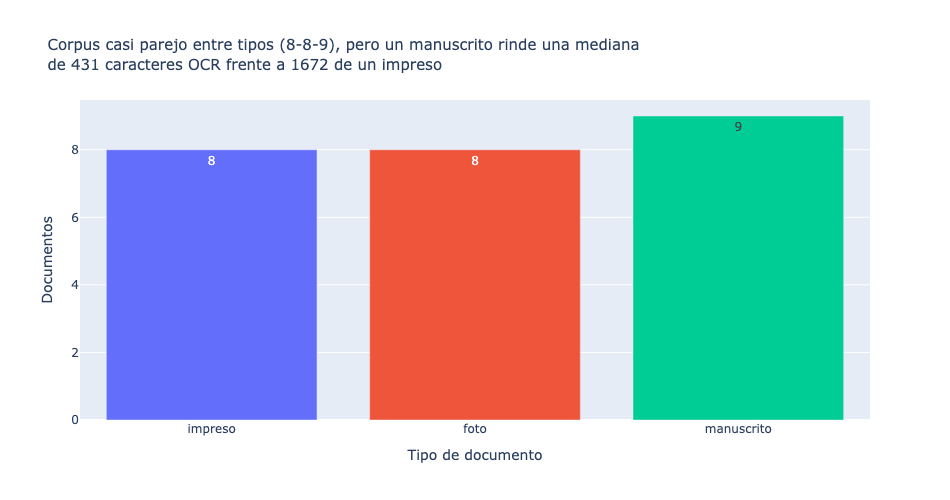

In [27]:
documentos["palabras"] = documentos["texto_ocr"].str.split().str.len()
audios["palabras"] = audios["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len()

por_tipo = documentos.groupby("tipo").agg(documentos=("id", "count"), caracteres=("n_caracteres", "median")).reset_index()
caracteres_impreso = por_tipo.loc[por_tipo["tipo"] == "impreso", "caracteres"].iloc[0]
caracteres_manuscrito = por_tipo.loc[por_tipo["tipo"] == "manuscrito", "caracteres"].iloc[0]

fig = px.bar(
    por_tipo, x="tipo", y="documentos", color="tipo", text="documentos",
    hover_data={"caracteres": True},
    category_orders={"tipo": ["impreso", "foto", "manuscrito"]},
    labels={"tipo": "Tipo de documento", "documentos": "Documentos", "caracteres": "Caracteres OCR (mediana)"},
    title=(f"Corpus casi parejo entre tipos (8-8-9), pero un manuscrito rinde una mediana<br>de "
           f"{caracteres_manuscrito:.0f} caracteres OCR frente a {caracteres_impreso:.0f} de un impreso"),
)
fig.update_layout(showlegend=False, width=950, height=500, title_font_size=15, margin={"t": 100})
fig.write_html(CARPETA_GRAFICOS / "documentos_por_tipo.html")
fig.show()

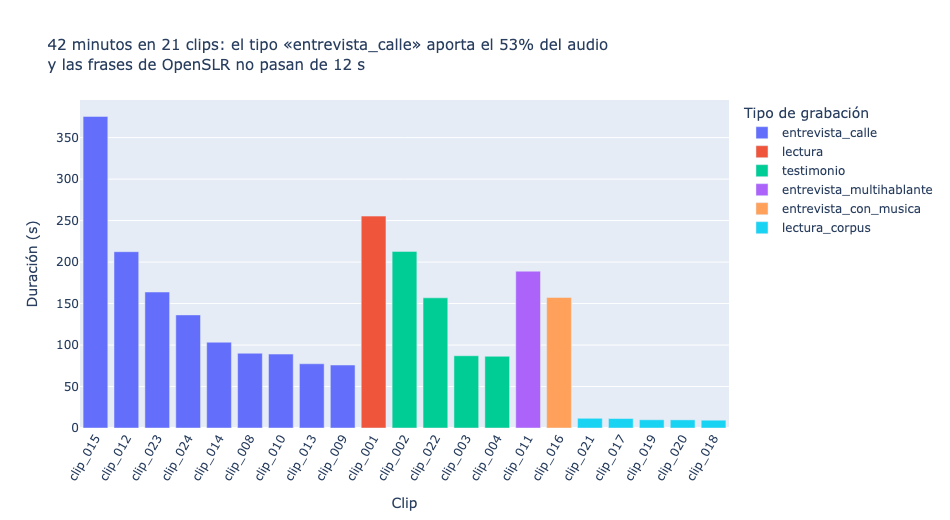

In [28]:
minutos_por_tipo = audios.groupby("tipo")["duracion_seg"].sum() / 60
tipo_principal = minutos_por_tipo.idxmax()
porcentaje_principal = 100 * minutos_por_tipo.max() / minutos_por_tipo.sum()
duracion_openslr = audios.loc[audios["tipo"] == "lectura_corpus", "duracion_seg"].max()

fig = px.bar(
    audios.sort_values("duracion_seg", ascending=False),
    x="id", y="duracion_seg", color="tipo",
    labels={"id": "Clip", "duracion_seg": "Duración (s)", "tipo": "Tipo de grabación"},
    title=(f"{audios['duracion_seg'].sum() / 60:.0f} minutos en {len(audios)} clips: el tipo «{tipo_principal}» "
           f"aporta el {porcentaje_principal:.0f}% del audio<br>y las frases de OpenSLR no pasan de {duracion_openslr:.0f} s"),
)
fig.update_layout(width=950, height=520, title_font_size=15, xaxis_tickangle=-60, margin={"t": 100})
fig.write_html(CARPETA_GRAFICOS / "duracion_por_clip.html")
fig.show()

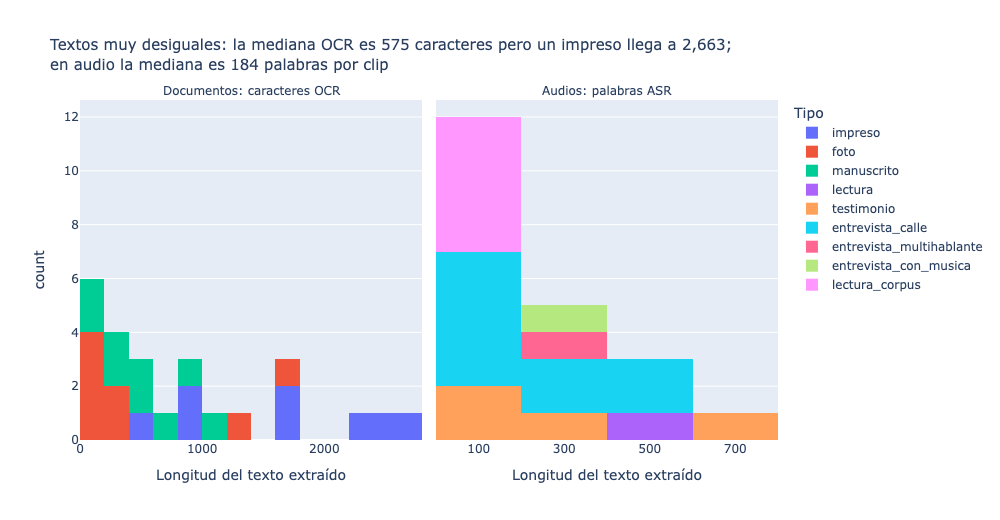

In [29]:
longitudes = pd.concat([
    pd.DataFrame({"medida": "Documentos: caracteres OCR", "longitud": documentos["n_caracteres"], "tipo": documentos["tipo"]}),
    pd.DataFrame({"medida": "Audios: palabras ASR", "longitud": audios["palabras"], "tipo": audios["tipo"]}),
])
mediana_ocr = documentos["n_caracteres"].median()
maximo_ocr = documentos["n_caracteres"].max()
tipo_maximo = documentos.loc[documentos["n_caracteres"].idxmax(), "tipo"]
mediana_asr = audios["palabras"].median()

fig = px.histogram(
    longitudes, x="longitud", facet_col="medida", color="tipo", nbins=15,
    labels={"longitud": "Longitud del texto extraído", "count": "Archivos", "tipo": "Tipo"},
    title=(f"Textos muy desiguales: la mediana OCR es {mediana_ocr:.0f} caracteres pero un {tipo_maximo} llega a "
           f"{maximo_ocr:,.0f};<br>en audio la mediana es {mediana_asr:.0f} palabras por clip"),
)
fig.update_xaxes(matches=None)
fig.for_each_annotation(lambda anotacion: anotacion.update(text=anotacion.text.split("=")[-1]))
fig.update_layout(width=1000, height=520, title_font_size=15, margin={"t": 100})
fig.write_html(CARPETA_GRAFICOS / "longitud_textos.html")
fig.show()

## 6. Validación: extremos frente a los histogramas

Los 3 documentos con más y con menos texto OCR, y los 3 clips más largos y más cortos. Deben coincidir con las colas de los histogramas: los impresos densos a la derecha y los manuscritos y placas a la izquierda; las entrevistas largas frente a las frases de OpenSLR.

In [30]:
columnas = ["id", "tipo", "titulo", "n_caracteres", "confianza_media"]
print("Documentos con MÁS texto OCR")
display(documentos.nlargest(3, "n_caracteres")[columnas])
print("Documentos con MENOS texto OCR")
display(documentos.nsmallest(3, "n_caracteres")[columnas])

Documentos con MÁS texto OCR


,id,tipo,titulo,n_caracteres,confianza_media
4,doc_005,impreso,"Tradiciones peruanas, tomo IV",2663,0.995324
3,doc_004,impreso,Gaceta del Gobierno (Lima),2551,0.982507
0,doc_001,impreso,"Mercurio Peruano, tomo V",2308,0.978227


Documentos con MENOS texto OCR


,id,tipo,titulo,n_caracteres,confianza_media
20,doc_021,manuscrito,Libro de Bautismos en la Gran Villa de Lampa 1655-1722,115,0.426237
24,doc_025,manuscrito,Peru revenue stamp on receipt,120,0.930346
12,doc_013,foto,Placa conmemorativa Mercado Minorista La Parada,162,0.977511


In [31]:
columnas = ["id", "tipo", "duracion_seg", "palabras", "n_hablantes"]
print("Clips MÁS largos")
display(audios.nlargest(3, "duracion_seg")[columnas])
print("Clips MÁS cortos")
display(audios.nsmallest(3, "duracion_seg")[columnas])

Clips MÁS largos


,id,tipo,duracion_seg,palabras,n_hablantes
11,clip_015,entrevista_calle,375.6,505,4
0,clip_001,lectura,255.4,532,1
1,clip_002,testimonio,212.9,681,1


Clips MÁS cortos


,id,tipo,duracion_seg,palabras,n_hablantes
14,clip_018,lectura_corpus,9.4,22,1
16,clip_020,lectura_corpus,9.8,20,1
15,clip_019,lectura_corpus,9.9,23,1


In [32]:
# Coherencia: más duración debería implicar más palabras transcritas.
correlacion = audios["duracion_seg"].corr(audios["palabras"])
print(f"Correlación duración–palabras en audio: {correlacion:.2f}")
print(f"Palabras por minuto (mediana): {(audios['palabras'] / audios['duracion_seg'] * 60).median():.0f}")

Correlación duración–palabras en audio: 0.90
Palabras por minuto (mediana): 122


## 7. Exportación

- `datos/documentos.csv` y `datos/transcripciones.csv` con las columnas obligatorias. `texto_referencia` queda vacía: se completa en la Parte 2 con las transcripciones manuales de la muestra de evaluación.
- `datos/fuentes.csv` con `id, modalidad, fuente_url, licencia, acceso` primero y el resto del registro de procedencia (incluido el hash SHA-256).

In [33]:
documentos["fuente"] = documentos["fuente"] + " (" + documentos["licencia"] + ")"
documentos["modelo_ocr"] = MODELO_OCR
documentos["texto_referencia"] = ""
documentos_csv = documentos[["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia",
                             "titulo", "fuente_url", "n_caracteres", "confianza_media"]]
documentos_csv.to_csv(CARPETA_DATOS / "documentos.csv", index=False)
print(documentos_csv.shape)
documentos_csv.head()

(25, 11)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,titulo,fuente_url,n_caracteres,confianza_media
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,archive.org (Dominio público),T0.\nPedro de Cancha; porque la voz Índica Cans significa incendio. Es-\ntos se distin...,"PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, sin desdoblado ni orientación de pá...",,"Mercurio Peruano, tomo V",https://archive.org/details/mercurioperuanod05cale/page/n15,2308,0.978227
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,archive.org (Dominio público),"V.\nSu Religion es la Católica, Apostólica, Romana, con exclusion del\nejercicio de cu...","PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, sin desdoblado ni orientación de pá...",,Bases de la Constitución política de la República Peruana,https://archive.org/details/basesdelaconstit00peru/page/n3,1614,0.983998
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,archive.org (Dominio público),"5\nCAPITULOIII.\nRELIJION.\nArt. 8. La Relijion de la Repùblica, es\nla Católica, Apos...","PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, sin desdoblado ni orientación de pá...",,Constitución política de la República Peruana,https://archive.org/details/constitucionpoli00peru/page/n8,920,0.987263
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,archive.org (Dominio público),"(NUM.I\nTOM.\n7.)\nGACETADELGOBIERNO\nDAL SABADO,1.= DE ENERO DE 1825.=6.° y=4.0\nAÑO ...","PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, sin desdoblado ni orientación de pá...",,Gaceta del Gobierno (Lima),https://archive.org/details/gacetadelgobiern00brow/page/n2,2551,0.982507
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,archive.org (Dominio público),"RICARDO PALMA\n13\nAjusticiados Gonzalo y sus tenientes Carvajal y Acosta, dejóse para...","PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, sin desdoblado ni orientación de pá...",,"Tradiciones peruanas, tomo IV",https://archive.org/details/tradicionesperua04palm/page/n20,2663,0.995324


In [34]:
audios["idioma"] = "es (configurado; español peruano según la fuente)"
audios["modelo_asr"] = MODELO_ASR_TEXTO
audios["texto_referencia"] = ""
audios["fuente"] = audios["fuente"] + " (" + audios["licencia"] + ")"
transcripciones_csv = audios[["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr",
                              "n_hablantes", "texto_referencia", "tipo", "diarizacion", "fuente", "fuente_url", "palabras"]]
transcripciones_csv.to_csv(CARPETA_DATOS / "transcripciones.csv", index=False)
print(transcripciones_csv.shape)
transcripciones_csv.head()

(21, 13)


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,tipo,diarizacion,fuente,fuente_url,palabras
0,clip_001,datos/raw/audio/clip_001.wav,255.4,es (configurado; español peruano según la fuente),"Huaca Cruz Hermatambo. La Huaca Cruz Hermatambo fue descubierta en los años 80, aproxi...","faster-whisper 1.2.1 large-v3-turbo (int8 CPU, beam 5, VAD on) + diarización sherpa-on...",1,,lectura,no aplica (un solo locutor),Wikimedia Commons (CC BY-SA 4.0),https://commons.wikimedia.org/wiki/File:Es-Huaca_Cruz_de_Armatambo-article.ogg,532
1,clip_002,datos/raw/audio/clip_002.wav,212.9,es (configurado; español peruano según la fuente),"Yo he ido a muchas salas de las que ya no existen y que ahora son otras cosas, ¿no? De...","faster-whisper 1.2.1 large-v3-turbo (int8 CPU, beam 5, VAD on) + diarización sherpa-on...",1,,testimonio,"estimada (umbral 0.7, mínimo 10 % de frases)",Wikimedia Commons (CC BY 4.0),"https://commons.wikimedia.org/wiki/File:Testimonio_2_-_Salas,_pantallas_y_archivos.ogg",681
2,clip_003,datos/raw/audio/clip_003.wav,87.1,es (configurado; español peruano según la fuente),"A ver, la primera vez que fui al cine fue el cine Callao, un cine normal, que ahora es...","faster-whisper 1.2.1 large-v3-turbo (int8 CPU, beam 5, VAD on) + diarización sherpa-on...",1,,testimonio,"estimada (umbral 0.7, mínimo 10 % de frases)",Wikimedia Commons (CC BY 4.0),"https://commons.wikimedia.org/wiki/File:Testimonio_3_-_Salas,_pantallas_y_archivos.ogg",166
3,clip_004,datos/raw/audio/clip_004.wav,86.4,es (configurado; español peruano según la fuente),"[HABLANTE_1] La primera sala que fui fue, hoy en día es Electra, que está acá en Sespe...","faster-whisper 1.2.1 large-v3-turbo (int8 CPU, beam 5, VAD on) + diarización sherpa-on...",3,,testimonio,"estimada (umbral 0.7, mínimo 10 % de frases)",Wikimedia Commons (CC BY 4.0),"https://commons.wikimedia.org/wiki/File:Testimonio_6_-_Salas,_pantallas_y_archivos.ogg",163
4,clip_008,datos/raw/audio/clip_008.wav,90.1,es (configurado; español peruano según la fuente),[HABLANTE_1] ¿Qué es el Perú para mí? [HABLANTE_2] Siento parte de la cultura pegana. ...,"faster-whisper 1.2.1 large-v3-turbo (int8 CPU, beam 5, VAD on) + diarización sherpa-on...",2,,entrevista_calle,"estimada (umbral 0.7, mínimo 10 % de frases)",Wikimedia Commons (CC BY-SA 4.0),https://commons.wikimedia.org/wiki/File:Entrevista_en_Magdalena_por_Fiestas_Patrias_Pe...,59


In [35]:
fuentes["en_corpus"] = "sí"
fuentes.loc[fuentes["id"].isin(list(CLIPS_OTRO_IDIOMA)), "en_corpus"] = "no: audio en quechua (reserva para el caso de quechua de Huaylas)"
columnas_fuentes = ["id", "modalidad", "fuente_url", "licencia", "acceso", "tipo", "titulo", "descripcion",
                    "autor", "fuente", "atribucion", "url_descarga", "archivo_original", "fecha_original",
                    "sha256", "en_corpus"]
fuentes[columnas_fuentes].to_csv(CARPETA_DATOS / "fuentes.csv", index=False)
print(fuentes[columnas_fuentes].shape)
fuentes[columnas_fuentes].head()

(49, 16)


,id,modalidad,fuente_url,licencia,acceso,tipo,titulo,descripcion,autor,fuente,atribucion,url_descarga,archivo_original,fecha_original,sha256,en_corpus
0,doc_001,documento,https://archive.org/details/mercurioperuanod05cale/page/n15,Dominio público,Descarga directa con `python datos.py documento` (imagen de página de archive.org),impreso,"Mercurio Peruano, tomo V",Página de periódico ilustrado limeño del siglo XVIII,Sociedad de Amantes del País,archive.org,"«Mercurio Peruano, tomo V» (1792), Sociedad de Amantes del País. Dominio público, esca...",https://archive.org/download/mercurioperuanod05cale/page/n15_w1800.jpg,datos/raw/documentos/doc_001.jpg,1792,eb2d7b3594c534d7ba8747a2844b76f25753daa48c2535f092a00a9335b3e0ee,sí
1,doc_002,documento,https://archive.org/details/basesdelaconstit00peru/page/n3,Dominio público,Descarga directa con `python datos.py documento` (imagen de página de archive.org),impreso,Bases de la Constitución política de la República Peruana,Folleto oficial impreso en Lima,Congreso Constituyente del Perú,archive.org,"«Bases de la Constitución política de la República Peruana» (1822), Congreso Constituy...",https://archive.org/download/basesdelaconstit00peru/page/n3_w1800.jpg,datos/raw/documentos/doc_002.jpg,1822,2abf85ccfc1dfc236824ddc1433b4e70c7ce26364ca12cb4f075a16f97658f1b,sí
2,doc_003,documento,https://archive.org/details/constitucionpoli00peru/page/n8,Dominio público,Descarga directa con `python datos.py documento` (imagen de página de archive.org),impreso,Constitución política de la República Peruana,Página de la primera Constitución del Perú,Congreso Constituyente del Perú,archive.org,"«Constitución política de la República Peruana» (1823), Congreso Constituyente del Per...",https://archive.org/download/constitucionpoli00peru/page/n8_w1800.jpg,datos/raw/documentos/doc_003.jpg,1823,f043c4d1139802755787af8edf9d7e83f2a9b41ac668ef3536b74a871b531b5d,sí
3,doc_004,documento,https://archive.org/details/gacetadelgobiern00brow/page/n2,Dominio público,Descarga directa con `python datos.py documento` (imagen de página de archive.org),impreso,Gaceta del Gobierno (Lima),Primera plana de periódico oficial,Gobierno del Perú,archive.org,"«Gaceta del Gobierno (Lima)» (1825), Gobierno del Perú. Dominio público, escaneo de ar...",https://archive.org/download/gacetadelgobiern00brow/page/n2_w1800.jpg,datos/raw/documentos/doc_004.jpg,1825,a1332cdd52489c2264a915f897212e2d8786babbe1e26e38b87e74951aca10ee,sí
4,doc_005,documento,https://archive.org/details/tradicionesperua04palm/page/n20,Dominio público,Descarga directa con `python datos.py documento` (imagen de página de archive.org),impreso,"Tradiciones peruanas, tomo IV",Página de libro con texto denso a una columna,Ricardo Palma,archive.org,"«Tradiciones peruanas, tomo IV» (1893), Ricardo Palma. Dominio público, escaneo de arc...",https://archive.org/download/tradicionesperua04palm/page/n20_w1800.jpg,datos/raw/documentos/doc_005.jpg,1893,f796c85000bf10b49d735f1b9917e18e35679422bf7d2616b2d22f0f6d3d7923,sí


## Resumen de lo hecho

| Paso | Qué se hizo | Código clave |
|---|---|---|
| Registro | 49 archivos (25 documentos, 24 audios) con URL, licencia y atribución | `pd.read_csv("datos/fuentes.csv")` |
| Descartes | 23 imágenes iniciales sin licencia o fuera de tipo | tabla `descartes_iniciales` |
| Duplicados | Hash SHA-256 de cada archivo | `hashlib.sha256(...)` |
| OCR | PaddleOCR PP-OCRv6 en 25 imágenes, con respaldo crudo y recortes | `ocr.predict(imagen)` |
| ASR | faster-whisper large-v3-turbo con VAD; 3 clips en quechua descartados y reemplazados | `voz.transcribir(modelo, wav)` |
| Diarización | pyannote-seg-3.0 + ERes2Net en entrevistas (n=3 fijado en `clip_011`) | `voz.diarizar(diarizador, wav)` |
| Seudonimización | Reglas + lista de revisión humana | `voz.seudonimizar(texto, NOMBRES_PRIVADOS)` |
| EDA | 3 gráficos Plotly con títulos analíticos | `px.bar`, `px.histogram` |
| Exportación | `documentos.csv`, `transcripciones.csv`, `fuentes.csv` | `df.to_csv(...)` |